# Lab 3 (new): Multiclass Classification with the Iris Dataset

We follow the same learning sequence as the original lab: exploratory data analysis (EDA), preprocessing, a train/test split, logistic regression, model diagnostics, feature importance, ROC and precision–recall curves, K-nearest neighbors (KNN), and lastly model comparison. A final scikit-learn pipeline is used to show the automation of the whole pipeline

Because Iris has three species, this version treats the task as multiclass classification. The target classes are setosa, versicolor, and virginica.

**Documentation-link convention:** Every code cell after the EDA heading has a Markdown explanation immediately above it. Each explanation contains clearly labelled, clickable links to the official documentation for the functions introduced in that cell.


## Goal of this lab

Imagine you are helping a team of biologists catalogue many flowers. They have measured each flower, but identifying every species manually takes time. Your task is to test whether four simple measurements can predict a flower’s species. A reliable first-pass classifier could help biologists organise samples, decide which flowers need expert review, and identify species that may be worth studying further, including for possible medicinal research.

Your goal is to build and evaluate logistic regression and K-nearest neighbors (KNN) models that can support this identification/classification task. You will inspect and prepare the data, compare the models, investigate where their predictions are reliable or incorrect, and finish by putting the workflow into a pipeline.

The models are not replacing expert judgement here: the important data-science skill is learning how to test whether a model is useful before relying on its predictions.


## 1. Load the Iris dataset

The Iris dataset contains 150 flowers, four numeric measurements, and one species label. We use the version bundled with scikit-learn so the lab does not need an external dataset download.


### What this code does

Import the libraries, load Iris as a dataframe, turn the numeric target into readable species names, and remove the original numeric target column.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn load_iris function documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)
- [Click to open the official pandas DataFrame.drop method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html)


In [3]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris(as_frame=True)
data = iris.frame.copy()
data["species"] = data["target"].map(dict(enumerate(iris.target_names)))
data = data.drop(columns=["target"])
target_names = iris.target_names

data.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


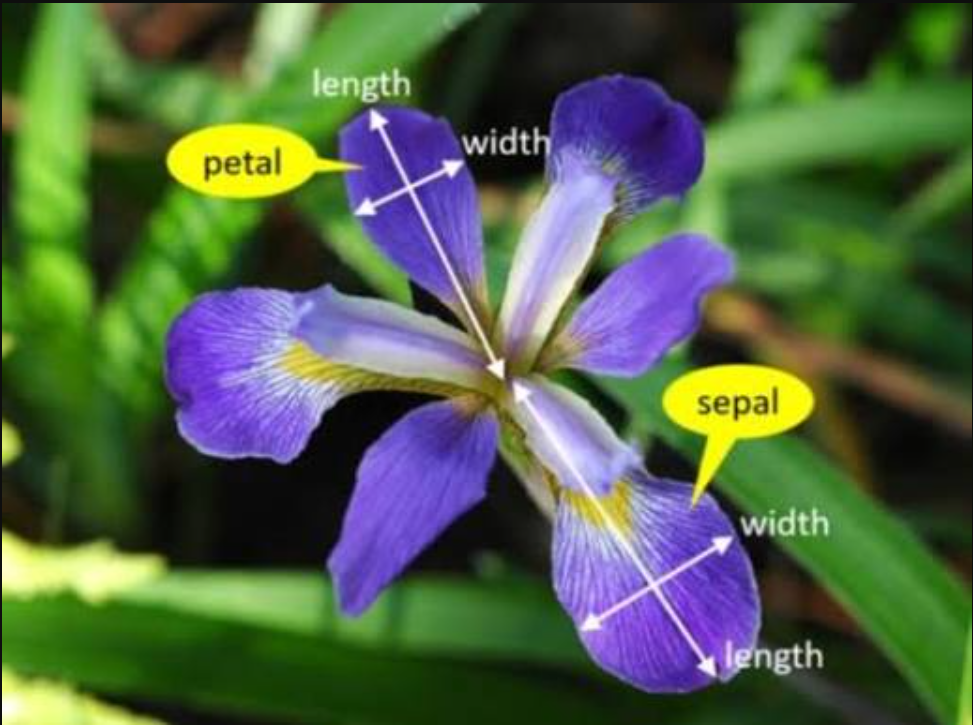

# 2. Exploratory data analysis (EDA)

EDA helps us understand the table before fitting a model. We first inspect its rows, data types, and summary statistics.


### What this code does

Show the first rows, inspect column types and non-missing counts, and calculate descriptive statistics for the numeric columns.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.head method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
- [Click to open the official pandas DataFrame.info method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)
- [Click to open the official pandas DataFrame.describe method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)


In [4]:
pd.set_option('display.float_format', '{:.2f}'.format)

# display vs print (https://www.geeksforgeeks.org/pandas/display-vs-print-in-pandas/) for your own interest.
display(data.head())
data.info()
display(data.describe())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.10,3.50,1.40,0.20,setosa
1,4.90,3.00,1.40,0.20,setosa
2,4.70,3.20,1.30,0.20,setosa
3,4.60,3.10,1.50,0.20,setosa
4,5.00,3.60,1.40,0.20,setosa


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### General overview

Iris has 150 observations, four numeric predictor columns, and one categorical target column named species. The four measurements are recorded in centimetres. There are three classes with 50 observations each.


### Missing values

Before modelling, check whether any measurements are missing. Iris is a clean teaching dataset, so we expect this check to find no missing values.


### What this code does

Check every column for missing values and add the counts together so we can see whether any imputation is required.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.isna method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html)
- [Click to open the official pandas Series.sum method documentation](https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html)


In [5]:
missing_values = data.isna().sum()
print("Missing values in each column:")
print(missing_values)


Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


### Handling missing values

There are no missing values in the Iris dataset. So we can continue with exploratory data analysis.


### Class balance and distributions

In classification tasks is extremely important to know class balance and the distribution of every numeric feature. It is frequent that there is a significant class imbalance. In those cases we should use methods such as SMOTE, ANN etc. but these methods are outside  the scope of this lab.


### What this code does

Count observations in each species and draw a bar chart so that class balance is visible rather than inferred from the printed counts.

**Documentation links — click the links below:**

- [Click to open the official pandas Series.value_counts method documentation](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
- [Click to open the official seaborn countplot function documentation](https://seaborn.pydata.org/generated/seaborn.countplot.html)


Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


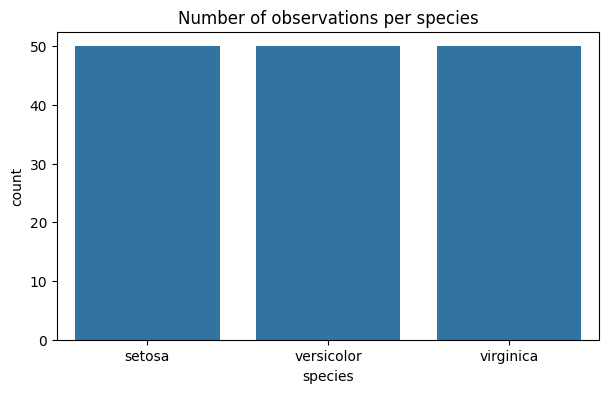

In [6]:
print("Class distribution:")
print(data["species"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="species", order=target_names)
plt.title("Number of observations per species")
plt.show()


### The classes are balanced. 

Class balance is not always required, but substantial class imbalance can bias a classifier toward the majority class and make accuracy misleading. Therefore, class proportions should be inspected and class-specific metrics should be reported.

## Visualise the numeric features

### What this code does

Create one histogram for each numeric feature to inspect its range and shape.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.hist method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html)
- [Click to open the official Matplotlib pyplot.suptitle function documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.suptitle.html)


In [7]:
numeric_features = []

# Coding challenge:
# iterate for each column through data.columns, if the column is different than "species" then append that column to the numeric features (add them to the list numeric_features)
# for 
 #   if 
    # append   

for c in data.columns: 
    if c =! "species", 
        append(numeric_features)



# Visualize the numeric features using histogram
data[numeric_features].____(figsize=(12, 8), bins=15, edgecolor="black")
plt.____("Histograms of Iris measurements")
plt.tight_layout()
plt.show()


SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (1122313019.py, line 10)

### Correlation heatmap and pairplot

Correlation helps us inspect linear relationships among numeric columns. A pairplot then shows how pairs of measurements separate the three species.


### Converting categorical variables with `pd.get_dummies()`

Machine-learning models generally require numerical input. However, some variables are categorical, meaning that their values represent groups or labels rather than numerical quantities. 

For example, the variable `Species` contains categories:

- `setosa`
- `versicolor`
- `virginica`

We should not simply convert these categories to `0`, `1`, and `2`, because that would incorrectly suggest that `virginica` is “larger” than `versicolor`.

Instead, we use **one-hot encoding**. This creates one new binary column for each category:

- `1` means that the observation belongs to that category.
- `0` means that it does not.

In our example:
In the Iris dataset, the variable `Species` contains categorical values:

- `setosa`
- `versicolor`
- `virginica`

We can convert these categories into numerical columns using `pd.get_dummies()`:

```python
import pandas as pd

iris_example = pd.DataFrame({
    "Species": ["setosa", "versicolor", "virginica", "setosa"]
})

iris_encoded = pd.get_dummies(
    iris_example,
    columns=["Species"],
    dtype=int
)

iris_encoded
```

The result is:

|   | Species_setosa | Species_versicolor | Species_virginica |
|---|----------------|--------------------|-------------------|
| 0 | 1              | 0                  | 0                 |
| 1 | 0              | 1                  | 0                 |
| 2 | 0              | 0                  | 1                 |
| 3 | 1              | 0                  | 0                 |

**Notice** that The original species column has been replaced by three new columns. 
Together, these columns contain the same information as the original categorical column, but in a numerical format that machine-learning models can use.

**One-hot encoding** is a very important technique in Machine Learning.



### What this code does

One-hot encode the species column for a numeric correlation table, calculate the correlation matrix, and display it as a heatmap.

**Documentation links — click the links below:**

- [Click to open the official pandas get_dummies function documentation](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
- [Click to open the official pandas DataFrame.corr method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) (corr was explained in the previous lab in the short EDA example. You can find a full explanation there.)
- [Click to open the official seaborn heatmap function documentation](https://seaborn.pydata.org/generated/seaborn.heatmap.html) (heatmap was explained in the previous lab in the short EDA example. Matplotlib was used to make the heatmap in Lab 2 but using seaborn is much simpler to create the same effect. You can find a full explanation there.))


In [ ]:
data_encoded = pd.____(data, columns=["species"], dtype=int)
correlation_matrix = data_encoded.____(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.____(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()


### What this code does

Draw scatterplots for all pairs of Iris measurements and colour the points by species so that class separation can be inspected visually.

**Documentation links — click the links below:**

- [Click to open the official seaborn pairplot function documentation](https://seaborn.pydata.org/generated/seaborn.pairplot.html)


In [ ]:
sns.____(data, hue="species", palette="husl")
plt.suptitle("Pairplot of Iris measurements", y=1.02)
plt.show()

# explanation below


### Understanding a pair plot

A pair plot shows the relationship between every pair of numerical variables in the dataset. In the Iris dataset, each dot represents one flower.

The argument `hue="species"` gives each species a different colour. This allows us to see whether the species form separate groups based on their measurements.

#### How to read the plot

Each column represents a variable on the x-axis, and each row represents a variable on the y-axis.

For example, the panel in the `petal_length` row and `petal_width` column shows:

- `petal_length` on the x-axis
- `petal_width` on the y-axis
- One point for each flower
- Different colours for the three species

If the points form an upward pattern, the two variables have a positive relationship. If they form a downward pattern, they have a negative relationship. If the points are spread randomly, there may be little relationship between the variables.

#### The diagonal panels

The diagonal panels are different from the other panels. They do not show a relationship between two variables. Instead, they show the distribution of one variable.

For example, the diagonal panel for `petal_length` shows how frequently different petal lengths occur.

The diagonal is useful for seeing:

- The typical values of a variable
- The spread of the observations
- Whether the values form separate groups
- Whether a variable has an unusual shape or extreme values

#### Why are some plots repeated?

The upper and lower parts of the pair plot show the same relationships in reverse order. For example:

- `petal_length` versus `petal_width`
- `petal_width` versus `petal_length`

These panels contain the same information, so the repetition is normal.

#### What can we observe in the Iris dataset?

The pair plot usually shows that:

- `petal_length` and `petal_width` separate the species particularly well.
- `setosa` forms a clearly separate cluster because it has much smaller petals.
- `versicolor` and `virginica` overlap more than `setosa` and are therefore harder to distinguish.
- The sepal measurements show more overlap between the species.
- The petal variables appear to be more useful for classification than the sepal variables.

A pair plot is different from a correlation heatmap. The heatmap summarizes relationships using correlation values, while the pair plot shows the individual observations. This makes it possible to see clusters, overlap, outliers, and patterns that a single correlation value may hide.

# 3. Preprocessing

The measurements are numeric, but their scales are not identical. We standardize the predictors before using distance-based KNN and before fitting the manually preprocessed logistic regression model.


### What this code does

Separate the standardized predictor matrix X from the integer target vector y. The species text column is removed because the model should only receive numeric predictors. 

*Also*, we remove the **target** columns of the model in order not to **leak** the answers to the model. 

- [Explanation of target leakage](https://www.ibm.com/think/topics/data-leakage-machine-learning)

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.drop method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html)
- [Click to open the official pandas column selection guide documentation](https://pandas.pydata.org/docs/user_guide/indexing.html)


In [ ]:
X = data.____(columns=["species"])

print("Predictor columns:", list(X.columns))



Predictor columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### What this code does

Convert the readable species labels into integer class codes. Keeping target_names separately lets us use readable names in reports and plots later. This is mainly for our test sample to assign true labels that match integers but also 

**Documentation links — click the links below:**

- [Click to open the official pandas Categorical function documentation](https://pandas.pydata.org/docs/reference/api/pandas.Categorical.html)
- [Click to open the official pandas categorical codes property documentation](https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.html)


In [ ]:

y = pd.____(
    data["species"],
    categories=target_names
).____


### Splitting the data

Use a 70–30 train/test split. stratify=y keeps the same class proportions in both subsets.


### What this code does

Split the standardized predictors and target into training and testing subsets. The fixed random state makes the result reproducible and stratification preserves the three-class balance.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn train_test_split documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)


In [ ]:
from sklearn.model_selection import ____

X_train, X_test, y_train, y_test = ____(
    X, y, test_size=0.30, random_state=17, stratify=y)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 105
Testing observations: 45


### What this code does

Create a StandardScaler, fit it using the numeric features, and store the standardized values in a separate DataFrame so the original measurements remain available for the pipeline section.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn StandardScaler documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Click to open the official scikit-learn fit_transform method documentation](https://scikit-learn.org/stable/glossary.html#term-fit_transform)
- [Click to open the official scikit-learn transform method documentation](https://scikit-learn.org/stable/glossary.html#term-transform)
- [Click to open the official pandas DataFrame.copy method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.copy.html)


### Standardizing features with `StandardScaler`

Different numerical variables can have very different scales. For example, one variable might range from `0` to `1`, while another ranges from `0` to `1,000`.

If we use these variables directly, the variable with the larger numerical values may have a stronger influence on the model, even if it is not actually more important.

`StandardScaler` solves this problem by standardizing each feature separately.

For every feature, it calculates:

- The mean
- The standard deviation

It then transforms each value using:

$
z = \frac{x - \mu}{\sigma}
$

where:

- \(x\) is the original value
- \(μ\) is the mean of the feature
- \(σ) is the standard deviation
- \(z\) is the standardized value

After standardization, each feature has approximately:

- Mean equal to `0`
- Standard deviation equal to `1`

For example, if a feature has a mean of `5.8` and a standard deviation of `0.8`, then a value of `6.6` becomes:

$
z = \frac{6.6 - 5.8}{0.8} = 1
$

This means that `6.6` is one standard deviation above the feature's mean.

A standardized value can be interpreted as follows:

- `0`: exactly average
- `1`: one standard deviation above average
- `-1`: one standard deviation below average
- `2`: two standard deviations above average

Standardization does not change the order of the observations. It only changes the scale in which the values are represented. It also does not force all values to lie between `0` and `1`.

### Why do we use it?

Standardization is especially important for algorithms that depend on distances or feature scales.

For example, KNN calculates distances between observations. Suppose one feature ranges from `0` to `1` and another ranges from `0` to `100`. Without standardization, the second feature could dominate the distance calculation simply because its numbers are larger.

Standardization is also useful for logistic regression because it:

- Places the features on comparable scales
- Makes the model easier to optimize
- Makes the effect of regularization more consistent across features
- Makes the coefficients easier to compare

Other algorithms that often benefit from standardization include SVM, PCA, and neural networks.

Tree-based models, such as decision trees and random forests, generally do not require standardization because they split observations based on thresholds rather than distances.

Since it is a linear transformation, it does not affect logistic regression. But for most models, it is a good practice to use standarize the data.

In [ ]:
from sklearn.preprocessing import ____

scaler = ____()

X_train[numeric_features] = scaler.____(
    X_train[numeric_features]
)

X_test[numeric_features] = scaler.____(
    X_test[numeric_features]
)


## The order of operations is very important

If we do not first **split** the data and **THEN** perform standarization on **only** the training data, we would be leaking information from training to test. This would mean inflated performance from our model, which is hard to spot. 

This is known as **Train-test contamination**.

- [Explanation of Train-test contamination leakage](https://www.ibm.com/think/topics/data-leakage-machine-learning)

### What this code does

Inspect the prepared predictor table and its column labels before splitting the data.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.head method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
- [Click to open the official pandas Index object documentation documentation](https://pandas.pydata.org/docs/reference/api/pandas.Index.html)


In [ ]:
display(X_train.head())
display(X_train.columns)

display(X_test.head())
display(X_test.columns)


# 4. Logistic regression: multiclass baseline


### What this code does

Import logistic regression and the metrics used to evaluate a multiclass classifier. Weighted averaging accounts for all three classes while respecting their support.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Click to open the official scikit-learn classification metrics documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)


In [ ]:
from sklearn.linear_model import ____
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)


### What this code does

Create an unregularized logistic regression classifier, fit it on the training set, and generate predictions for the held-out test set. With three classes, scikit-learn handles multiclass classification internally.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Click to open the official scikit-learn estimator fit method documentation](https://scikit-learn.org/stable/glossary.html#term-fit)
- [Click to open the official scikit-learn estimator predict method documentation](https://scikit-learn.org/stable/glossary.html#term-predict)


In [ ]:
baseline_logistic_model = ____(
    l1_ratio=0, random_state=17, max_iter=1000
)
baseline_logistic_model.____(X_train, y_train)
baseline_logistic_predictions = baseline_logistic_model.____(X_test)


### What this code does

y_test contains the correct species labels for the test observations. baseline_logistic_predictions contains the species predicted by the logistic regression model.
- Accuracy measures the proportion of all predictions that are correct.
- Precision measures how often predictions for a class are correct.
- Recall measures how many of the actual observations of a class were found.
- F1-score combines precision and recall into one measure.
The argument average="weighted" first calculates the metric separately for each species. It then averages the species-specific scores while giving more influence to species with more observations. This is useful when classes are imbalanced. Scikit-learn defines weighted averaging using each class's number of true observations, called its support.



**Documentation links — click the links below:**

- [Click to open the official scikit-learn accuracy_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)
- [Click to open the official scikit-learn precision_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html)
- [Click to open the official scikit-learn recall_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html)
- [Click to open the official scikit-learn f1_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
- [Click to open the official scikit-learn classification_report documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)


In [ ]:
baseline_accuracy = accuracy_score(y_test, baseline_logistic_predictions)

baseline_precision = precision_score(y_test, baseline_logistic_predictions, average="weighted")

baseline_recall = recall_score(y_test, baseline_logistic_predictions, average="weighted")

baseline_f1 = f1_score(y_test, baseline_logistic_predictions, average="weighted")

print(f"Accuracy: {baseline_accuracy:.3f}")
print(f"Weighted precision: {baseline_precision:.3f}")
print(f"Weighted recall: {baseline_recall:.3f}")
print(f"Weighted F1 score: {baseline_f1:.3f}")

print(classification_report(y_test, baseline_logistic_predictions, target_names=target_names))


### What this code does

Create a confusion matrix and annotate it with species names. Rows are the true species and columns are the predicted species.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn confusion_matrix documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Click to open the official seaborn heatmap function documentation](https://seaborn.pydata.org/generated/seaborn.heatmap.html)
- [Click to open the official Matplotlib subplots function documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)


In [ ]:
cm = ____(y_test, baseline_logistic_predictions)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=ax,
)
ax.set_xlabel("Predicted species")
ax.set_ylabel("True species")
ax.set_title("Logistic regression confusion matrix")
plt.show()


## Feature importance for logistic regression

For multiclass logistic regression, there is one coefficient row per class. A positive coefficient means that larger values of the corresponding standardized feature push the model toward that class relative to the other classes.


### What this code does

Extract the coefficient matrix, label its rows by species, and calculate the mean absolute coefficient for each feature as a compact overall importance measure.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Click to open the official pandas DataFrame.abs method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.abs.html)
- [Click to open the official pandas DataFrame.mean method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html)
- [Click to open the official pandas DataFrame.sort_values method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html)


In [ ]:
# Search in the logistic regression dcoumentation for the coefficient attribute and use it to extract the coefficients
coefficients_df = pd.DataFrame(
    baseline_logistic_model.____, index=target_names, columns=X.columns
)
display(coefficients_df)

importance_df = (
    coefficients_df.____()
    .____(axis=0)
    .____(ascending=True)
    .to_frame("Mean absolute coefficient")
)
display(importance_df)


### What this code does

Plot the mean absolute coefficient for each feature. Larger values indicate that the feature has a stronger average influence on the linear decision functions.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame.plot method documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html)
- [Click to open the official Matplotlib tight_layout function documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html)


In [ ]:
importance_df.____(kind="barh", legend=False, figsize=(8, 4))
plt.title("Average logistic-regression feature importance")
plt.xlabel("Mean absolute coefficient")
plt.tight_layout()
plt.show()


# 5. ROC curves and precision–recall curves

For multiclass classification, we use a one-vs-rest view: one ROC or precision–recall curve is calculated for each species against the other two species.


### What this code does

Convert the test labels to one-vs-rest indicator columns, obtain class probabilities, calculate macro-averaged multiclass ROC AUC, and plot one ROC curve per species.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn label_binarize documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.label_binarize.html)
- [Click to open the official scikit-learn estimator predict_proba method documentation](https://scikit-learn.org/stable/glossary.html#term-predict_proba)
- [Click to open the official scikit-learn roc_curve documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
- [Click to open the official scikit-learn roc_auc_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)


In [ ]:
from sklearn.preprocessing import ____
from sklearn.metrics import ____, ____

y_test_binarized = ____(y_test, classes=np.arange(len(target_names)))
baseline_probabilities = baseline_logistic_model.____(X_test)
baseline_roc_auc = ____(
    y_test, baseline_probabilities, multi_class="ovr", average="macro"
)

plt.figure(figsize=(8, 6))
for class_index, class_name in enumerate(target_names):
    fpr, tpr, _ = ____(
        y_test_binarized[:, class_index], baseline_probabilities[:, class_index]
    )
    plt.plot(fpr, tpr, label=class_name)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"One-vs-rest ROC curves (macro AUC = {baseline_roc_auc:.3f})")
plt.legend()
plt.show()


### What this code does

Use Youden's J statistic (true-positive rate minus false-positive rate) to find a separate illustrative probability threshold for each one-vs-rest ROC curve.

**Documentation links — click the links below:**

- [Click to open the official NumPy argmax function documentation](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html)
- [Click to open the official scikit-learn roc_curve documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)


In [ ]:
def get_optimal_threshold(fpr, tpr, thresholds):
    youden_j = tpr - fpr
    return thresholds[np.____(youden_j)]

optimal_thresholds = {}
for class_index, class_name in enumerate(target_names):
    fpr, tpr, thresholds = roc_curve(
        y_test_binarized[:, class_index], baseline_probabilities[:, class_index]
    )
    optimal_thresholds[class_name] = get_optimal_threshold(fpr, tpr, thresholds)

In [ ]:
print("Illustrative one-vs-rest thresholds:")

for classes, optimal_threshold_values in optimal_thresholds.items():

    classes.strip("np.str_('")
    str(optimal_threshold_values).strip(" np.float64(")
    
    print(f"The optimal value for class {classes} is {optimal_threshold_values}", )


### What this code does

Calculate and plot one precision–recall curve per species, and report the average precision for each one-vs-rest problem.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn precision_recall_curve documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html)
- [Click to open the official scikit-learn average_precision_score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)


In [ ]:
from sklearn.metrics import ____, ____

plt.figure(figsize=(8, 6))
for class_index, class_name in enumerate(target_names):
    precision, recall, _ = ____(
        y_test_binarized[:, class_index], baseline_probabilities[:, class_index]
    )
    average_precision = ____(
        y_test_binarized[:, class_index], baseline_probabilities[:, class_index]
    )
    plt.plot(recall, precision, label=f"{class_name} (AP = {average_precision:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("One-vs-rest precision–recall curves")
plt.legend()
plt.show()

# 6. K-nearest neighbors (KNN)

KNN classifies a new observation using the labels of nearby training observations. Because KNN uses distances, the standardized predictors from the preprocessing section are important.


### What this code does

Create a KNN classifier with five neighbors, fit it on the training data, and predict the species of the test observations.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn KNeighborsClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- [Click to open the official scikit-learn estimator fit method documentation](https://scikit-learn.org/stable/glossary.html#term-fit)
- [Click to open the official scikit-learn estimator predict method documentation](https://scikit-learn.org/stable/glossary.html#term-predict)


In [ ]:
from sklearn.neighbors import ____

knn = ____(n_neighbors=5)
knn.____(X_train, y_train)
knn_predictions = knn.____(X_test)


### What this code does

Evaluate KNN with the same multiclass metrics used for logistic regression so the comparison is fair.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn classification metrics documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)


In [ ]:
knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_precision = precision_score(y_test, knn_predictions, average=____)
knn_recall = recall_score(y_test, knn_predictions, average=____)
knn_f1 = f1_score(y_test, knn_predictions, average=____)

print(f"Accuracy: {knn_accuracy:.3f}")
print(f"Weighted precision: {knn_precision:.3f}")
print(f"Weighted recall: {knn_recall:.3f}")
print(f"Weighted F1-score: {knn_f1:.3f}")
print(classification_report(y_test, knn_predictions, target_names=target_names))


### What this code does

Plot the KNN confusion matrix with the same row and column labels used for logistic regression.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn confusion_matrix documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Click to open the official seaborn heatmap function documentation](https://seaborn.pydata.org/generated/seaborn.heatmap.html)


In [ ]:
knn_cm = ____(y_test, knn_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.xlabel("Predicted species")
plt.ylabel("True species")
plt.title("KNN confusion matrix")
plt.show()


In [ ]:
# Create a DataFrame to compare metrics of both models
comparison_metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [baseline_accuracy, baseline_precision, baseline_recall, baseline_f1],
    'KNN': [knn_accuracy, knn_precision, knn_recall, knn_f1]
})

# Plot the metrics as a grouped bar plot
comparison_metrics_df.set_index('Metric').plot(kind='bar', figsize=(10, 6), color=['steelblue', 'orange'], alpha=0.8, edgecolor='black')

# Add labels and title
plt.ylabel('Score')
plt.title('Comparison of Model Performance Metrics')
plt.ylim([0, 1])
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Model')
plt.xticks(rotation=0)

# Annotate the bars with their values
for i, col in enumerate(comparison_metrics_df.columns[1:]):
    for j, value in enumerate(comparison_metrics_df[col]):
        plt.text(j + i * 0.2 - 0.1, value + 0.02, f'{value:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# 7. Model comparison


### What this code does

Put the main test-set metrics for both models into one DataFrame and display them side by side.

**Documentation links — click the links below:**

- [Click to open the official pandas DataFrame constructor documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html)


In [ ]:
comparison_metrics_df = pd.DataFrame(
    {
        "Accuracy": [baseline_accuracy, knn_accuracy],
        "Weighted precision": [baseline_precision, knn_precision],
        "Weighted recall": [baseline_recall, knn_recall],
        "Weighted F1-score": [baseline_f1, knn_f1],
    },
    index=["Logistic regression", "KNN"],
)
display(comparison_metrics_df)


# 8. Pipeline

The final section rebuilds the workflow as a scikit-learn pipeline. The pipeline receives the original, unscaled numeric features and performs scaling inside the model workflow. Iris has no categorical predictors, so an encoder step is not needed here.


### What this code does

Import Pipeline and create a two-step workflow: standardize the numeric predictors, then fit unregularized logistic regression and KNN.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn Pipeline documentation](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [Click to open the official scikit-learn StandardScaler documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Click to open the official scikit-learn LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)


In [ ]:
from sklearn.pipeline import ____

models = {
    "Logistic Regression": ____([
        ("scaler", ____()),
        (
            "model",
            ____(
                random_state=17,
                max_iter=1000
            )
        )
    ]),

    "KNN": ____([
        ("scaler", ____()),
        (
            "model",
            ____(n_neighbors=5)
        )
    ])
}



### What this code does

Prepare the original unscaled predictors for the pipeline and create a matching stratified train/test split. The pipeline will learn scaling parameters only from its training subset.

**Documentation links — click the links below:**

- [Click to open the official pandas column selection guide documentation](https://pandas.pydata.org/docs/user_guide/indexing.html)
- [Click to open the official pandas Categorical function documentation](https://pandas.pydata.org/docs/reference/api/pandas.Categorical.html)
- [Click to open the official scikit-learn train_test_split documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)


In [ ]:
X_pipeline = data[numeric_features]
y_pipeline = pd.____(data["species"], categories=target_names).____

X_train_pipeline, X_test_pipeline, y_train_pipeline, y_test_pipeline = ____(
    ____,
    ____,
    test_size=0.30,
    random_state=17,
    stratify=____,
)


### What this code does

Fit the complete pipeline on the pipeline training data, predict the held-out observations, and print the final pipeline metrics. Also, plot the pipeline confusion matrix.

**Documentation links — click the links below:**

- [Click to open the official scikit-learn Pipeline documentation](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [Click to open the official scikit-learn classification metrics documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)
- [Click to open the official scikit-learn confusion_matrix documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Click to open the official seaborn heatmap function documentation](https://seaborn.pydata.org/generated/seaborn.heatmap.html)



In [ ]:
for model_name, model_pipeline in models.items():
    model_pipeline.____(X_train_pipeline, y_train_pipeline)
    pipeline_predictions = model_pipeline.____(X_test_pipeline)

    pipeline_accuracy = accuracy_score(y_test_pipeline, pipeline_predictions)
    pipeline_f1 = f1_score(y_test_pipeline, pipeline_predictions, average=____)
    print(f"Pipeline accuracy: {pipeline_accuracy:.3f}")
    print(f"Pipeline weighted F1-score: {pipeline_f1:.3f}")
    print(
        classification_report(
            y_test_pipeline, pipeline_predictions, target_names=target_names
        )
    )
    
    pipeline_cm = ____(y_test_pipeline, pipeline_predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        pipeline_cm,
        annot=True,
        fmt="d",
        cmap="Purples",
        xticklabels=target_names,
        yticklabels=target_names,
    )
    plt.xlabel("Predicted species")
    plt.ylabel("True species")
    plt.title("Pipeline confusion matrix")
    plt.show()



## Reflection

1. Which two Iris measurements appear most useful for separating the species in the pairplot?
2. How do the logistic-regression and KNN confusion matrices differ?
3. Why is standardization especially important for KNN?
4. What does the pipeline protect us from when preprocessing is part of model fitting?
